# JuriPredict: figuras das TEDs 02 e 03 no Google Colab

Reproduz as 11 figuras de `docs/JuriPredict_Documento_Tecnico_BigData.pdf`, com as mesmas funções dos scripts de `src/` e o scikit-learn.

**Como usar:** no Colab, *Arquivo > Fazer upload de notebook* e escolha este arquivo. Depois, *Ambiente de execução > Executar tudo*. Se a primeira célula instalar versões novas, a sessão reinicia sozinha; nesse caso, mande executar tudo de novo.

**Dados:** a célula da TED 01 baixa a base [Brazilian Legal Proceedings](https://www.kaggle.com/datasets/felipepolo/brazilian-legal-proceedings) (versão 2, 658 MB) direto do Kaggle, sem conta, e confere o SHA-256. Nada é enviado para fora do Colab.

**Tempo:** cerca de 13 minutos em um notebook com 8 GB de memória; o Colab gratuito, com 2 processadores, tende a levar mais. A limpeza percorre 2,9 milhões de movimentações para montar o léxico de nomes, e a busca de hiperparâmetros do E6 treina 100 modelos.

**Reprodução:** executado com as versões da primeira célula, o notebook gerou as 11 figuras idênticas às do PDF. Em outra máquina, as posições 7 e 8 da Figura 7 podem variar na terceira casa decimal, porque o treino nessas posições é instável e depende da quantidade de threads.

Ficaram de fora as tabelas que não viram figura (experimentos E3 a E5, intervalos por *bootstrap*, generalização e verificação com o DataJud); o código delas está em `src/ted03_modelar.py`.

## Versões das bibliotecas

In [1]:
import importlib.metadata as md
import os, subprocess, sys

# Versões de src/requirements.txt, as mesmas que geraram os números do PDF.
VERSOES = {"numpy": "2.5.4", "pandas": "3.1.0", "scipy": "1.18.1", "scikit-learn": "1.9.1",
           "matplotlib": "3.11.2", "joblib": "1.6.0"}


def instalada(pacote):
    try:
        return md.version(pacote)
    except md.PackageNotFoundError:
        return None


faltam = [f"{p}=={v}" for p, v in VERSOES.items() if instalada(p) != v]
if faltam:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *faltam], check=True)
    print("Versões instaladas. A sessão será reiniciada: depois, use Ambiente de execução > Executar tudo de novo.")
    os.kill(os.getpid(), 9)
print("versões conferidas:", VERSOES)

versões conferidas: {'numpy': '2.5.4', 'pandas': '3.1.0', 'scipy': '1.18.1', 'scikit-learn': '1.9.1', 'matplotlib': '3.11.2', 'joblib': '1.6.0'}


## Configuração

Constantes, expressões de mascaramento e estilo dos gráficos, copiados de `src/ted02_limpar_e_explorar.py` e `src/ted03_modelar.py`.

In [2]:
import hashlib, json, mmap, os, re, time, unicodedata, urllib.request, warnings, zipfile
from collections import Counter
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.feature_selection import chi2
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, balanced_accuracy_score, classification_report, confusion_matrix, f1_score
from sklearn.model_selection import GridSearchCV, StratifiedGroupKFold, cross_validate, learning_curve
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=matplotlib.MatplotlibDeprecationWarning)

DADOS = Path("dados")  # no Colab, /content/dados
RAW = DADOS / "raw"
FIGURAS = Path("figuras")  # cada figura também é gravada em PNG, como no PDF
# Mesmo valor usado nos números do PDF. Esse número muda as threads de cada processo e, com isso, a
# terceira casa decimal das posições 7 e 8 da Figura 7, cujo treino é instável (F1 perto de 0,44).
N_JOBS = 3

CLASSES = ["arquivado", "ativo", "suspenso"]
CORES = {"arquivado": "#2a78d6", "ativo": "#eb6834", "suspenso": "#1baf7a"}
TINTA = "#52514e"
ANO_MIN, ANO_MAX = 1990, 2021  # a base foi publicada em maio de 2021
LIMITE_CHARS = 2000  # próximo do percentil 99 do tamanho das movimentações
JANELA = 5  # últimas movimentações que identificam casos praticamente iguais
TOKEN = r"(?u)\b[^\W\d_]{2,}\b"

MASCARAS = [
    ("tkcnj", re.compile(r"\b\d{7}-?\d{2}\.?\d{4}\.?\d\.?\d{2}\.?\d{4}\b")),
    ("tkdoc", re.compile(r"\b\d{3}\.\d{3}\.\d{3}-\d{2}\b|\b\d{2}\.\d{3}\.\d{3}/\d{4}-\d{2}\b")),
    ("tkoab", re.compile(r"\bOAB[\s/:.-]*[A-Z]{0,2}[\s/:.-]*\d[\d.]*(?:[\s/-]*[A-Z]{2})?", re.I)),
    ("tkemail", re.compile(r"\b[\w.+-]+@[\w-]+\.[\w.-]+\b")),
    ("tkvalor", re.compile(r"R\$\s*[\d.,]+")),
    ("tkdata", re.compile(r"\b\d{1,2}/\d{1,2}/\d{2,4}\b")),
    ("tknum", re.compile(r"\b\d[\d./-]*\b")),
]
DATA = re.compile(r"\b(\d{2})/(\d{2})/(\d{4})\b")
PREFIXO_CAMPOS = "Tipo do Movimento:"
CONTROLE = re.compile(r"[\x00-\x1f\x7f-\x9f]+")
ESPACOS = re.compile(r"\s+")
PALAVRA = re.compile(r"[^\W\d_]+")
MAIUSCULA = r"[A-ZÀ-Ý][\w'’.-]*"
SEQUENCIA_NOME = rf"{MAIUSCULA}(?:\s+(?:(?:de|da|do|dos|das|e|D[aeo]s?)\s+)?{MAIUSCULA})*"
# Nomes aparecem antes do número da OAB ou depois de quem é a pessoa no processo.
SEQUENCIA = re.compile(SEQUENCIA_NOME)
PAR_JSON = re.compile(rb'"(?:[^"\\]|\\.)*":\s*("(?:[^"\\]|\\.)*")')
NOME_ANTES_OAB = re.compile(rf"({SEQUENCIA_NOME})[\s,(-]*OAB\b")
NOME_APOS_PAPEL = re.compile(
    rf"\b(?i:parte|autora?|r[ée]u|r[ée]|exequente|executad[oa]|requerente|requerid[oa]|advogad[oa]s?(?:\(s\))?"
    rf"|dra?\.?|ju[ií]za?)\s*:?\s+({SEQUENCIA_NOME})")
# Órgãos, siglas e termos de sistema que vêm sempre em maiúscula, mas não são nomes de pessoa.
NAO_NOMES = frozenset("""
    advogada advogado advogados bacenjud brasil câmara cep cível cnpj colégio corregedoria cpc cpf csm defensoria
    del depre descrição diário disponibilização diversas djerj dje egrégio fazenda ffpa fesp fórum imesc inss
    instaurado int interna intermediária iii juiz juíza juizado judiciário ltda ministério ministro movimento ncpc
    número oab página praticado procuradoria proger publicável regional reprografia restrito rio saj seq sidap
    situacão sorteio status stf stj supremo tribunal turma vara wfpa wjmj
    adi cdc cejusc comercio conselho cump deecrim delegacia desembargador dju empreendimentos fedtj infância ipesp
    oja presidente república secretaria spprev sucessões viii vossa
    advogadoadvogado agrg câm câmaras cidadania colendo cpp digitados dpvat iirgd júri nscgj prog reativados xiv xvi
""".split())
# Sobrenomes achados na auditoria dos termos de maior peso do modelo. Também são palavras comuns
# em minúscula, por isso o filtro do léxico os rejeita.
SOBRENOMES_AUDITADOS = frozenset("angelo guerra parada paula sá vintena".split())

SEMENTE = 42
JANELAS = [1, 2, 3, 5, 10, 20, 50, None]


def estilo(ax):
    ax.spines[["top", "right"]].set_visible(False)
    ax.spines[["left", "bottom"]].set_color("#c9c8c2")
    ax.tick_params(colors=TINTA, length=0)
    ax.xaxis.label.set_color(TINTA)
    ax.yaxis.label.set_color(TINTA)


def salvar(fig, nome):
    """Grava a figura com a mesma resolução do PDF e a mostra no notebook."""
    FIGURAS.mkdir(parents=True, exist_ok=True)
    fig.savefig(FIGURAS / nome, dpi=200, bbox_inches="tight", facecolor="white")
    plt.show()

## TED 01: download e conferência da base

In [3]:
URL = "https://www.kaggle.com/api/v1/datasets/download/felipepolo/brazilian-legal-proceedings/{}"
# Versão 2 da base, publicada em 14/05/2021.
SHA256 = {
    "labeled.json": "653013a741af31ad389f44458bc0bf5fd4c78a380646556d0772dee47846c63a",
    "unlabeled.json": "0451bc19da272cd849a25e510d44ad1735f42a51436514eff114bba7fece3042",
}


def sha256(caminho):
    h = hashlib.sha256()
    with open(caminho, "rb") as f:
        while bloco := f.read(1 << 20):
            h.update(bloco)
    return h.hexdigest()


def baixar(nome):
    destino = RAW / nome
    if not destino.exists():
        RAW.mkdir(parents=True, exist_ok=True)
        compactado = destino.with_suffix(".zip")
        print(f"baixando {nome}...")
        urllib.request.urlretrieve(URL.format(nome), compactado)
        with zipfile.ZipFile(compactado) as z:
            z.extract(nome, RAW)
        compactado.unlink()
    obtido = sha256(destino)
    if obtido != SHA256[nome]:
        raise SystemExit(f"{nome}: SHA-256 {obtido} difere da versão documentada")
    return destino

In [4]:
inicio = time.time()
for nome in SHA256:
    baixar(nome)
    print(f"{nome}: {(RAW / nome).stat().st_size} bytes, SHA-256 conferido")
print(f"{(time.time() - inicio) / 60:.1f} min")

labeled.json: 127627741 bytes, SHA-256 conferido


unlabeled.json: 530110583 bytes, SHA-256 conferido
0.0 min


## TED 02: limpeza e mascaramento

Normaliza o texto, monta o léxico de nomes a partir dos próprios textos (rotulados e sem rótulo), mascara nomes, documentos, OAB, e-mails, valores, datas e números, trunca cada movimentação em 2.000 caracteres e remove processos duplicados (seções 6.1 e 6.2 do PDF).

In [5]:
def textos_json_plano(caminho):
    """Percorre os valores de um JSON {id: texto} sem carregar o arquivo inteiro na memória."""
    with open(caminho, "rb") as f, mmap.mmap(f.fileno(), 0, access=mmap.ACCESS_READ) as dados:
        for par in PAR_JSON.finditer(dados):
            yield json.loads(par[1])


def normalizar(texto):
    """Unifica a codificação (o NBSP vira espaço) e remove quebras e caracteres de controle."""
    texto = unicodedata.normalize("NFKC", texto or "")
    return ESPACOS.sub(" ", CONTROLE.sub(" ", texto)).strip()


def mascarar(texto, contagem=None):
    for marca, padrao in MASCARAS:
        texto, n = padrao.subn(marca, texto)
        if contagem is not None:
            contagem[marca] += n
    return texto


def construir_lexico(textos):
    """Palavras usadas como nome de pessoa e que quase nunca aparecem em minúscula.

    A segunda condição preserva termos jurídicos capturados por engano. Palavras que abrem
    movimentações (Despacho, Decisão) também ficam de fora, porque nomeiam o tipo do ato.
    Uma segunda passada (por isso `textos` precisa ser uma lista) acrescenta as palavras coladas
    a um nome já conhecido, como sobrenomes que nunca aparecem junto da OAB.
    ponytail: heurística; nome isolado de qualquer outro nome conhecido escapa.
    Se isso pesar, trocar por um reconhecedor de entidades treinado em textos jurídicos.
    """
    candidatos, minusculas, maiusculas, iniciais = Counter(), Counter(), Counter(), Counter()

    def limpo(bruto):
        # O limite é o mesmo da limpeza: o que passa dele não chega à base tratada.
        return normalizar(bruto).removeprefix(PREFIXO_CAMPOS).strip()[:LIMITE_CHARS]

    for bruto in textos:
        texto = limpo(bruto)
        for padrao in (NOME_ANTES_OAB, NOME_APOS_PAPEL) if "OAB" in texto else (NOME_APOS_PAPEL,):
            for trecho in padrao.findall(texto):
                candidatos.update(p.lower() for p in PALAVRA.findall(trecho) if len(p) >= 3)
        palavras = PALAVRA.findall(texto)
        if palavras:
            iniciais[palavras[0].lower()] += 1
        for p in palavras:
            (maiusculas if p[0].isupper() else minusculas)[p.lower()] += 1

    def aceita(p):
        return p not in NAO_NOMES and minusculas[p] < 0.02 * maiusculas[p] and iniciais[p] < 0.02 * maiusculas[p]

    lexico = {p for p in candidatos if aceita(p)}
    vizinhos = set()
    for bruto in textos:
        for trecho in SEQUENCIA.findall(limpo(bruto)):
            palavras = [p.lower() for p in PALAVRA.findall(trecho) if len(p) >= 3]
            if len(palavras) > 1 and not lexico.isdisjoint(palavras):
                vizinhos.update(palavras)
    return lexico | {p for p in vizinhos if aceita(p)} | SOBRENOMES_AUDITADOS


def mascarar_nomes(texto, lexico, contagem=None):
    def trocar(m):
        return "tknome" if m[0][0].isupper() and m[0].lower() in lexico else m[0]

    texto = re.sub(r"tknome(?:\s+(?:(?:de|da|do|dos|das|e)\s+)?tknome)+", "tknome", PALAVRA.sub(trocar, texto))
    if contagem is not None:
        contagem["tknome"] += sum(1 for p in PALAVRA.findall(texto) if p == "tknome")
    return texto


def limpar_movimentacao(texto, contagem=None, lexico=frozenset()):
    texto = normalizar(texto)
    if texto.startswith(PREFIXO_CAMPOS):
        texto = texto[len(PREFIXO_CAMPOS):].strip()
    return mascarar(mascarar_nomes(texto, lexico, contagem), contagem)[:LIMITE_CHARS]


def ano_referencia(textos_recentes):
    """Maior ano válido entre as datas citadas; datas impossíveis ou futuras são ignoradas."""
    anos = [
        int(a)
        for t in textos_recentes
        for d, m, a in DATA.findall(t)
        if 1 <= int(d) <= 31 and 1 <= int(m) <= 12 and ANO_MIN <= int(a) <= ANO_MAX
    ]
    return max(anos) if anos else None


def preparar(bruto, lexico):
    contagem = Counter()
    linhas = []
    for pid, proc in bruto.items():
        # A chave -1 é a movimentação mais recente, -2 a anterior, e assim por diante.
        ordem = sorted(proc["texts"], key=lambda k: -int(k))
        originais = [proc["texts"][k] for k in ordem]
        contagem["com_nbsp_ou_controle"] += sum(
            1 for t in originais if "\xa0" in t or CONTROLE.search(t)
        )
        contagem["acima_do_limite"] += sum(1 for t in originais if len(normalizar(t)) > LIMITE_CHARS)
        contagem["com_ano_invalido"] += sum(
            1 for t in originais
            for d, m, a in DATA.findall(t)
            if not (1 <= int(d) <= 31 and 1 <= int(m) <= 12 and ANO_MIN <= int(a) <= ANO_MAX)
        )
        n_campos = sum(1 for t in originais if t.startswith(PREFIXO_CAMPOS))
        movs = [limpar_movimentacao(t, contagem, lexico) for t in originais]
        contagem["vazias_apos_limpeza"] += sum(1 for m in movs if not m)
        contagem["repetidas_em_sequencia"] += sum(1 for a, b in zip(movs, movs[1:]) if a == b)
        janela = " | ".join(movs[:JANELA]).lower()
        linhas.append({
            "id": pid,
            "classe": proc["label"].removeprefix("H:").lower(),
            "origem": "RJ (provável)" if n_campos > len(originais) / 2 else "SP (provável)",
            "ano_ref": ano_referencia(originais[:10]),
            "n_mov": len(movs),
            "chars_total": sum(len(m) for m in movs),
            "chars_medio": round(sum(len(m) for m in movs) / len(movs), 1),
            "grupo": hashlib.sha1(janela.encode()).hexdigest()[:16],
            "movs": movs,
        })
    return linhas, contagem


def remover_duplicados(linhas):
    vistos, unicos = set(), []
    for linha in linhas:
        chave = (linha["classe"], tuple(linha["movs"]))
        if chave not in vistos:
            vistos.add(chave)
            unicos.append(linha)
    return unicos

In [6]:
inicio = time.time()
rotulado = json.loads((RAW / "labeled.json").read_text(encoding="utf-8"))
sem_rotulo = Counter(textos_json_plano(RAW / "unlabeled.json"))
lexico = construir_lexico([m for p in rotulado.values() for m in p["texts"].values()] + list(sem_rotulo))
linhas, contagem = preparar(rotulado, lexico)
n_bruto = len(linhas)
df = pd.DataFrame(remover_duplicados(linhas))
del rotulado, sem_rotulo, lexico, linhas  # libera memória: só a base tratada segue adiante
print(f"{(time.time() - inicio) / 60:.1f} min")
print(f"processos: {n_bruto} brutos, {n_bruto - len(df)} duplicados removidos, {len(df)} finais")
print(f"movimentações na base tratada: {df.n_mov.sum()}")
pd.Series(contagem, name="ocorrências")

4.8 min
processos: 6449 brutos, 86 duplicados removidos, 6363 finais
movimentações na base tratada: 539286


com_nbsp_ou_controle        6621
acima_do_limite             5116
com_ano_invalido             736
tknome                    459511
tkcnj                       7810
tkdoc                       1549
tkoab                     254533
tkemail                      317
tkvalor                     5395
tkdata                    193053
tknum                     807894
vazias_apos_limpeza            0
repetidas_em_sequencia     11322
Name: ocorrências, dtype: int64

## TED 02: análise exploratória

### Figura 1: Distribuição das classes por origem provável do processo

Seção 7.2 do PDF.

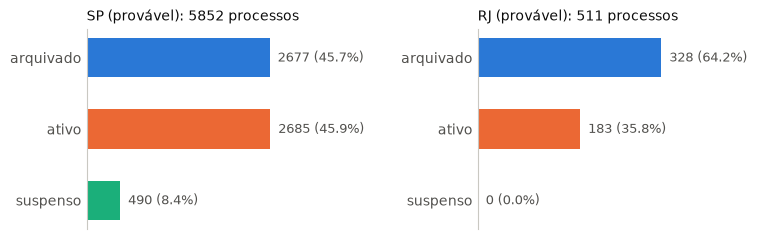

In [7]:
def fig_classes_origem(df):
    fig, eixos = plt.subplots(1, 2, figsize=(8.6, 2.6), sharex=False, gridspec_kw={"wspace": 0.42})
    for ax, origem in zip(eixos, ["SP (provável)", "RJ (provável)"]):
        parte = df[df.origem == origem]
        fatias = parte.classe.value_counts().reindex(CLASSES).fillna(0)
        ax.barh(CLASSES[::-1], fatias[CLASSES[::-1]], color=[CORES[c] for c in CLASSES[::-1]], height=0.55)
        for i, c in enumerate(CLASSES[::-1]):
            ax.text(fatias[c], i, f"  {int(fatias[c])} ({fatias[c] / len(parte):.1%})", va="center", color=TINTA, fontsize=9)
        ax.set_title(f"{origem}: {len(parte)} processos", loc="left", fontsize=10, color="#0b0b0b")
        ax.set_xlim(0, fatias.max() * 1.5)
        ax.set_xticks([])
        ax.spines["bottom"].set_visible(False)
        estilo(ax)
    salvar(fig, "fig_classes_origem.png")


fig_classes_origem(df)

### Figura 2: Número de movimentações por processo, por classe

Seção 7.3 do PDF.

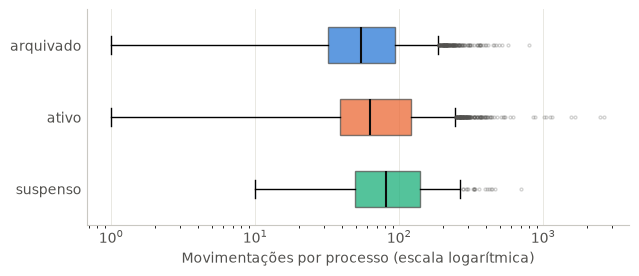

In [8]:
def fig_n_mov(df):
    fig, ax = plt.subplots(figsize=(7, 2.8))
    dados = [df.loc[df.classe == c, "n_mov"] for c in CLASSES[::-1]]
    caixa = ax.boxplot(dados, vert=False, widths=0.5, patch_artist=True, tick_labels=CLASSES[::-1],
                       flierprops={"marker": "o", "markersize": 2, "alpha": 0.25, "markeredgecolor": TINTA},
                       medianprops={"color": "#0b0b0b", "linewidth": 1.5})
    for patch, c in zip(caixa["boxes"], CLASSES[::-1]):
        patch.set(facecolor=CORES[c], alpha=0.75, edgecolor=TINTA)
    ax.set_xscale("log")
    ax.set_xlabel("Movimentações por processo (escala logarítmica)")
    ax.grid(axis="x", color="#e9e8e2", linewidth=0.7)
    ax.set_axisbelow(True)
    estilo(ax)
    salvar(fig, "fig_n_mov.png")


fig_n_mov(df)

### Figura 3: Participação de cada classe por ano de referência

Seção 7.4 do PDF.

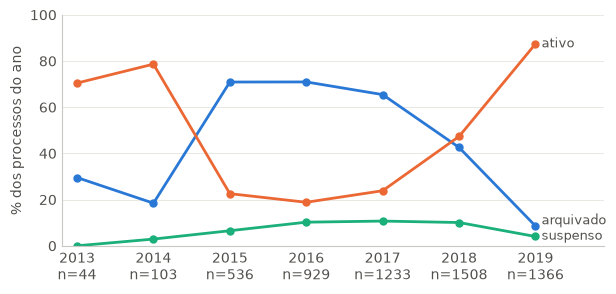

classe,arquivado,ativo,suspenso
ano_ref,,,
2013.0,13,31,0
2014.0,19,81,3
2015.0,380,121,35
2016.0,659,175,95
2017.0,807,294,132
2018.0,642,714,152
2019.0,117,1194,55


In [9]:
def fig_anos(df):
    anos = list(range(2013, 2020))
    tabela = df[df.ano_ref.isin(anos)].groupby(["ano_ref", "classe"]).size().unstack(fill_value=0).reindex(columns=CLASSES)
    fatias = tabela.div(tabela.sum(axis=1), axis=0)
    fig, ax = plt.subplots(figsize=(7, 3))
    # Rótulos no fim das linhas, afastados quando os valores do último ano ficam próximos.
    altura = {}
    for c in sorted(CLASSES, key=lambda c: fatias[c].iloc[-1]):
        altura[c] = max(fatias[c].iloc[-1] * 100, max(altura.values(), default=-100) + 7)
    for c in CLASSES:
        ax.plot(fatias.index, fatias[c] * 100, color=CORES[c], linewidth=2, marker="o", markersize=5)
        ax.text(fatias.index[-1] + 0.08, altura[c], c, color=TINTA, va="center", fontsize=9)
    ax.set_xticks(anos, [f"{a}\nn={int(tabela.loc[a].sum())}" for a in anos])
    ax.set_xlim(2012.8, 2019.9)
    ax.set_ylim(0, 100)
    ax.set_ylabel("% dos processos do ano")
    ax.grid(axis="y", color="#e9e8e2", linewidth=0.7)
    ax.set_axisbelow(True)
    estilo(ax)
    salvar(fig, "fig_anos.png")
    return tabela


fig_anos(df)

### Figura 4: Situação dos processos segundo expressões presentes na última movimentação

Seção 7.5 do PDF.

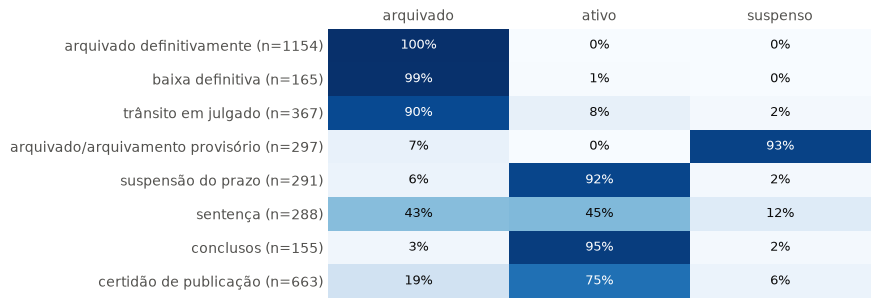

,expressao,n,arquivado,ativo,suspenso
0,arquivado definitivamente,1154,1152,2,0
1,baixa definitiva,165,164,1,0
2,trânsito em julgado,367,331,29,7
3,arquivado/arquivamento provisório,297,21,0,276
4,suspensão do prazo,291,18,267,6
5,sentença,288,124,129,35
6,conclusos,155,5,147,3
7,certidão de publicação,663,126,498,39


In [10]:
def fig_expressoes(df):
    padroes = {
        "arquivado definitivamente": r"arquivad[oa] definitiv",
        "baixa definitiva": r"baixa definitiva",
        "trânsito em julgado": r"tr[aâ]nsito em julgado",
        "arquivado/arquivamento provisório": r"arquivad[oa] provis|arquivamento provis",
        "suspensão do prazo": r"suspens[aã]o do prazo",
        "sentença": r"senten[cç]a",
        "conclusos": r"conclusos",
        "certidão de publicação": r"certid[aã]o de publica",
    }
    ultima = df.movs.str[0]
    linhas, proporcoes = [], []
    for rotulo, padrao in padroes.items():
        marcados = df[ultima.str.contains(padrao, case=False, regex=True)]
        cont = marcados.classe.value_counts().reindex(CLASSES).fillna(0).astype(int)
        linhas.append({"expressao": rotulo, "n": int(cont.sum()), **cont.to_dict()})
        proporcoes.append((cont / max(cont.sum(), 1)).values)
    matriz = np.array(proporcoes)
    fig, ax = plt.subplots(figsize=(7, 3.5))
    ax.imshow(matriz, cmap="Blues", vmin=0, vmax=1, aspect="auto")
    ax.set_xticks(range(3), CLASSES)
    ax.xaxis.tick_top()
    ax.set_yticks(range(len(linhas)), [f"{l['expressao']} (n={l['n']})" for l in linhas])
    for i in range(matriz.shape[0]):
        for j in range(3):
            ax.text(j, i, f"{matriz[i, j]:.0%}", ha="center", va="center", fontsize=9,
                    color="white" if matriz[i, j] > 0.55 else "#0b0b0b")
    ax.spines[:].set_visible(False)
    ax.tick_params(length=0, colors=TINTA)
    salvar(fig, "fig_expressoes.png")
    return linhas


pd.DataFrame(fig_expressoes(df))

### Figura 5: Termos mais associados a cada classe nas cinco últimas movimentações (estatística qui-quadrado)

Seção 7.6 do PDF.

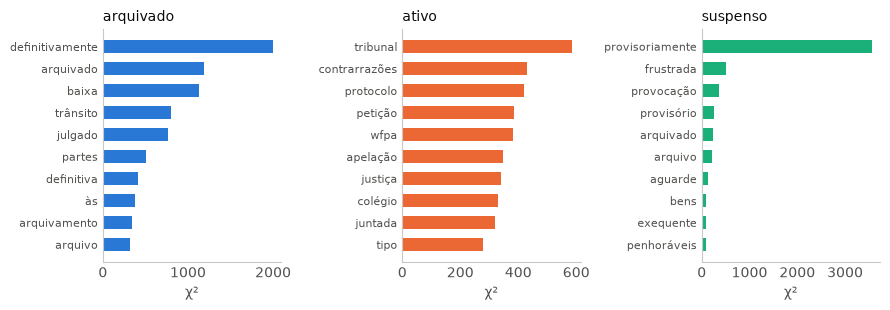

In [11]:
def termos_discriminantes(df, k=10):
    textos = df.movs.apply(lambda m: " ".join(m[:JANELA]))
    cv = CountVectorizer(binary=True, min_df=20, token_pattern=TOKEN, lowercase=True)
    X = cv.fit_transform(textos)
    nomes = np.array(cv.get_feature_names_out())
    # Só mantemos termos que aparecem em muitos processos: nomes de pessoas não chegam aqui.
    resultado = {}
    fig, eixos = plt.subplots(1, 3, figsize=(9, 3.2))
    for ax, c in zip(eixos, CLASSES):
        y = (df.classe == c).values
        score, _ = chi2(X, y)
        taxa_in = np.asarray(X[y].mean(axis=0)).ravel()
        taxa_out = np.asarray(X[~y].mean(axis=0)).ravel()
        score = np.where(taxa_in > taxa_out, score, 0)
        topo = np.argsort(score)[::-1][:k]
        resultado[c] = [{"termo": nomes[i], "chi2": round(float(score[i]), 1)} for i in topo]
        ax.barh(nomes[topo][::-1], score[topo][::-1], color=CORES[c], height=0.6)
        ax.set_title(c, loc="left", fontsize=10, color="#0b0b0b")
        ax.set_xlabel("χ²")
        ax.tick_params(axis="y", labelsize=8)
        estilo(ax)
    fig.tight_layout()
    salvar(fig, "fig_termos.png")
    return resultado


termos = termos_discriminantes(df)

## TED 03: modelagem

Separa 20% dos processos para teste antes de qualquer experimento, com estratificação por classe e agrupamento pelas cinco últimas movimentações (seção 8.4 do PDF).

In [12]:
def tfidf(**kw):
    base = dict(token_pattern=TOKEN, lowercase=True, ngram_range=(1, 2), min_df=2, sublinear_tf=True)
    return TfidfVectorizer(**{**base, **kw})


def lr(**kw):
    base = dict(C=10, class_weight="balanced", max_iter=3000, random_state=SEMENTE)
    return LogisticRegression(**{**base, **kw})


def janela(df, k):
    return df.movs.apply(lambda m: " ".join(m[:k] if k else m))


def com_colunas(df, k):
    """Separa a última movimentação das anteriores, para que o modelo saiba a posição do termo."""
    return pd.DataFrame({
        "ultima": df.movs.str[0],
        "anteriores": df.movs.apply(lambda m: " ".join(m[1:k]) or "vazio"),
        "log_n_mov": np.log1p(df.n_mov.values),
    }, index=df.index)


def cv_dev():
    return StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEMENTE)


def avaliar_cv(modelo, X, y, grupos):
    r = cross_validate(modelo, X, y, groups=grupos, cv=cv_dev(), scoring=["f1_macro", "accuracy"],
                       return_train_score=True, n_jobs=N_JOBS)
    return {
        "f1_macro": round(float(r["test_f1_macro"].mean()), 4),
        "f1_macro_dp": round(float(r["test_f1_macro"].std()), 4),
        "acuracia": round(float(r["test_accuracy"].mean()), 4),
        "f1_macro_treino": round(float(r["train_f1_macro"].mean()), 4),
        "f1_por_dobra": [round(float(v), 4) for v in r["test_f1_macro"]],
    }


def metricas(y, pred):
    relatorio = classification_report(y, pred, labels=CLASSES, output_dict=True, zero_division=0)
    # Só as classes que existem no recorte: uma classe sem exemplos derrubaria a média sem motivo.
    presentes = [c for c in CLASSES if c in set(y)]
    return {
        "acuracia": round(float(accuracy_score(y, pred)), 4),
        "acuracia_balanceada": round(float(balanced_accuracy_score(y, pred)), 4),
        "f1_macro": round(float(f1_score(y, pred, average="macro", labels=presentes, zero_division=0)), 4),
        "por_classe": {c: {k: round(float(relatorio[c][k]), 4) for k in ("precision", "recall", "f1-score", "support")} for c in CLASSES},
    }


def fig_linha(x, series, xlabel, ylabel, nome, rotulos_x=None, ylim=None):
    fig, ax = plt.subplots(figsize=(6.8, 2.9))
    for rotulo, y, cor in series:
        ax.plot(range(len(x)), y, color=cor, linewidth=2, marker="o", markersize=5)
        ax.text(len(x) - 1 + 0.12, y[-1], rotulo, color=TINTA, va="center", fontsize=9)
    ax.set_xticks(range(len(x)), rotulos_x or x)
    ax.set_xlim(-0.2, len(x) - 1 + (1.3 if len(series) > 1 else 0.3))
    if ylim:
        ax.set_ylim(*ylim)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.grid(axis="y", color="#e9e8e2", linewidth=0.7)
    ax.set_axisbelow(True)
    estilo(ax)
    salvar(fig, nome)


def preprocessador(numerico=True):
    """Última movimentação e anteriores em blocos separados de TF-IDF (arranjo do experimento E4)."""
    partes = [("ultima", tfidf(), "ultima"), ("anteriores", tfidf(), "anteriores")]
    if numerico:
        partes.append(("num", StandardScaler(), ["log_n_mov"]))
    return ColumnTransformer(partes)

In [13]:
y, grupos = df.classe.values, df.grupo.values
# Teste separado antes de tudo: uma dobra de cinco, sem dividir grupos e mantendo a proporção das classes.
dev_i, teste_i = next(StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEMENTE).split(df, y, grupos))
dev, teste = df.iloc[dev_i].reset_index(drop=True), df.iloc[teste_i].reset_index(drop=True)
assert not set(dev.grupo) & set(teste.grupo)
y_dev, g_dev = dev.classe.values, dev.grupo.values
print(f"desenvolvimento: {len(dev)} processos; teste: {len(teste)}")
teste.classe.value_counts()

desenvolvimento: 5090 processos; teste: 1273


classe
arquivado    601
ativo        574
suspenso      98
Name: count, dtype: int64

### Figura 6: F1 macro na validação cruzada segundo o número de movimentações usadas (E1)

Seção 8.6 do PDF.

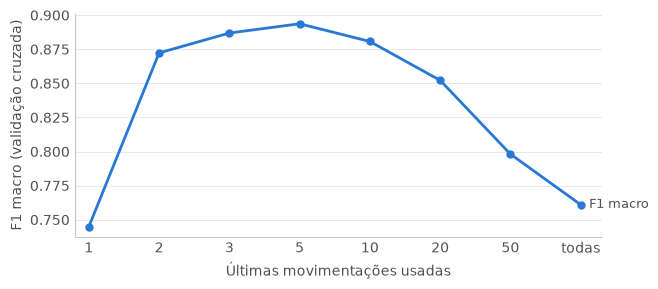

,f1_macro,f1_macro_dp,acuracia
1,0.7448,0.0125,0.8214
2,0.8723,0.0151,0.909
3,0.8869,0.0132,0.9238
5,0.8937,0.0099,0.9283
10,0.8807,0.0068,0.9222
20,0.8522,0.0132,0.9006
50,0.7981,0.0186,0.867
todas,0.761,0.0238,0.8462


In [14]:
e1 = {str(k or "todas"): avaliar_cv(make_pipeline(tfidf(), lr()), janela(dev, k), y_dev, g_dev) for k in JANELAS}
fig_linha([str(k or "todas") for k in JANELAS], [("F1 macro", [v["f1_macro"] for v in e1.values()], CORES["arquivado"])],
          "Últimas movimentações usadas", "F1 macro (validação cruzada)", "fig_janela.png")
pd.DataFrame(e1).T[["f1_macro", "f1_macro_dp", "acuracia"]]

### Figura 7: F1 macro usando apenas a movimentação de cada posição (E2)

Seção 8.6 do PDF.

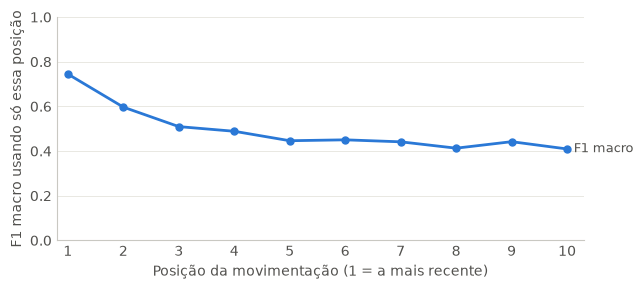

In [15]:
e2 = {}
for p in range(1, 11):
    tem = dev.n_mov >= p
    X = dev.movs[tem].apply(lambda m: m[p - 1])
    e2[str(p)] = {**avaliar_cv(make_pipeline(tfidf(), lr()), X, y_dev[tem], g_dev[tem]), "n": int(tem.sum())}
fig_linha(list(e2), [("F1 macro", [v["f1_macro"] for v in e2.values()], CORES["arquivado"])],
          "Posição da movimentação (1 = a mais recente)", "F1 macro usando só essa posição", "fig_posicao.png", ylim=(0, 1))

### Modelo final (E6)

Busca de hiperparâmetros por validação cruzada no arranjo com a última movimentação separada das quatro anteriores (seção 8.6 do PDF). Vence a combinação de maior F1 macro médio.

In [16]:
inicio = time.time()
Xc =com_colunas(dev, 5)
busca = GridSearchCV(
    make_pipeline(preprocessador(False), lr()),
    {
        "logisticregression__C": [1, 3, 10, 30, 100],
        "logisticregression__class_weight": ["balanced", None],
        "columntransformer__ultima__ngram_range": [(1, 1), (1, 2)],
    },
    scoring="f1_macro", cv=cv_dev(), n_jobs=N_JOBS, refit=True,
)
busca.fit(Xc, y_dev, groups=g_dev)
modelo = busca.best_estimator_
print(f"{(time.time() - inicio) / 60:.1f} min")
print("melhores hiperparâmetros:", busca.best_params_)
print(f"F1 macro na validação cruzada: {busca.best_score_:.4f}")

1.2 min
melhores hiperparâmetros: {'columntransformer__ultima__ngram_range': (1, 2), 'logisticregression__C': 30, 'logisticregression__class_weight': 'balanced'}
F1 macro na validação cruzada: 0.9006


### Figura 8: Matriz de confusão do modelo no teste (contagem e proporção da classe real)

Seção 8.7 do PDF.

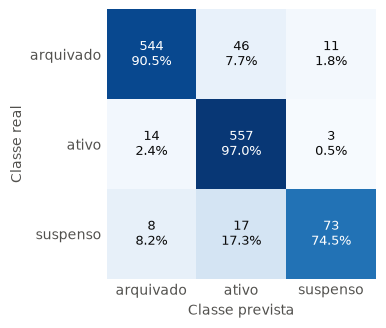

teste: F1 macro 0.8848, acurácia 0.9222, acurácia balanceada 0.8735


,precision,recall,f1-score,support
arquivado,0.9611,0.9052,0.9323,601.0
ativo,0.8984,0.9704,0.9330,574.0
suspenso,0.8391,0.7449,0.7892,98.0


In [17]:
def fig_confusao(matriz):
    fig, ax = plt.subplots(figsize=(4.4, 3.5))
    normal = matriz / matriz.sum(axis=1, keepdims=True)
    ax.imshow(normal, cmap="Blues", vmin=0, vmax=1)
    ax.set_xticks(range(3), CLASSES)
    ax.set_yticks(range(3), CLASSES)
    ax.set_xlabel("Classe prevista")
    ax.set_ylabel("Classe real")
    ax.xaxis.label.set_color(TINTA)
    ax.yaxis.label.set_color(TINTA)
    for i in range(3):
        for j in range(3):
            ax.text(j, i, f"{matriz[i, j]}\n{normal[i, j]:.1%}", ha="center", va="center", fontsize=9,
                    color="white" if normal[i, j] > 0.55 else "#0b0b0b")
    ax.spines[:].set_visible(False)
    ax.tick_params(length=0, colors=TINTA)
    salvar(fig, "fig_confusao.png")


Xt = com_colunas(teste, 5)
y_t = teste.classe.values
proba = modelo.predict_proba(Xt)
classes = modelo.steps[-1][1].classes_
pred = classes[proba.argmax(axis=1)]
fig_confusao(confusion_matrix(y_t, pred, labels=CLASSES))
m = metricas(y_t, pred)
print(f"teste: F1 macro {m['f1_macro']:.4f}, acurácia {m['acuracia']:.4f}, "
      f"acurácia balanceada {m['acuracia_balanceada']:.4f}")
pd.DataFrame(m["por_classe"]).T

### Figura 9: Termos de maior peso para cada classe no modelo final

Seção 8.8 do PDF.

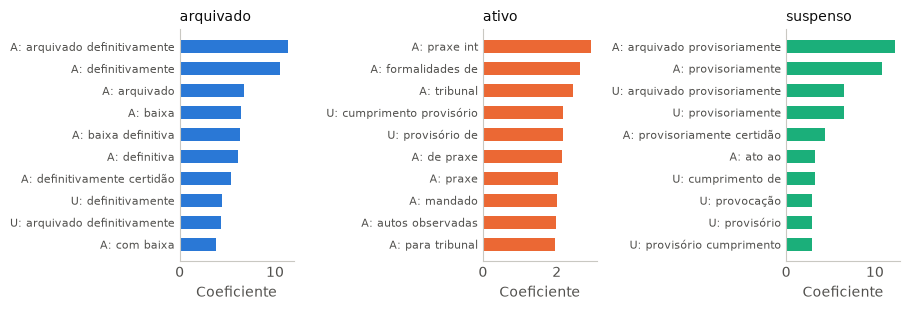

In [18]:
def fig_coeficientes(modelo, k=10):
    pre, clf = modelo.steps[0][1], modelo.steps[-1][1]
    nomes = pre.get_feature_names_out()
    saida = {}
    fig, eixos = plt.subplots(1, 3, figsize=(9.2, 3.2))
    for ax, classe, linha in zip(eixos, clf.classes_, clf.coef_):
        topo = np.argsort(linha)[::-1][:k]
        termos = [nomes[i].replace("ultima__", "U: ").replace("anteriores__", "A: ").replace("num__", "") for i in topo]
        saida[classe] = [{"termo": t, "coef": round(float(linha[i]), 2)} for t, i in zip(termos, topo)]
        ax.barh(termos[::-1], linha[topo][::-1], color=CORES[classe], height=0.6)
        ax.set_title(classe, loc="left", fontsize=10, color="#0b0b0b")
        ax.set_xlabel("Coeficiente")
        ax.tick_params(axis="y", labelsize=8)
        estilo(ax)
    fig.tight_layout()
    salvar(fig, "fig_coeficientes.png")
    return saida


coeficientes = fig_coeficientes(modelo)

### Figura 10: Acurácia e cobertura no teste segundo a confiança mínima exigida

Seção 8.9 do PDF.

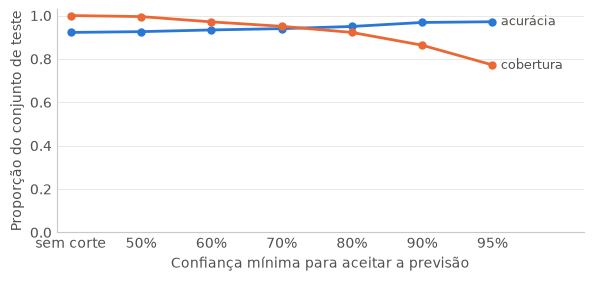

,cobertura,n,acuracia
limiar,,,
0.00,1.0000,1273,0.9222
0.50,0.9953,1267,0.9258
0.60,0.9709,1236,0.9337
0.70,0.9505,1210,0.9397
0.80,0.9222,1174,0.9497
0.90,0.8633,1099,0.9682
0.95,0.7722,983,0.9715


In [19]:
# Abstenção: até onde a confiança separa os casos que podem dispensar a conferência
conf = proba.max(axis=1)
abstencao = []
for limiar in [0, 0.5, 0.6, 0.7, 0.8, 0.9, 0.95]:
    aceitos = conf >= limiar
    abstencao.append({
        "limiar": limiar, "cobertura": round(float(aceitos.mean()), 4), "n": int(aceitos.sum()),
        "acuracia": round(float((pred[aceitos] == y_t[aceitos]).mean()), 4),
    })
fig_linha([f"{a['limiar']:.0%}" if a["limiar"] else "sem corte" for a in abstencao],
          [("acurácia", [a["acuracia"] for a in abstencao], CORES["arquivado"]),
           ("cobertura", [a["cobertura"] for a in abstencao], CORES["ativo"])],
          "Confiança mínima para aceitar a previsão", "Proporção do conjunto de teste", "fig_abstencao.png", ylim=(0, 1.03))
pd.DataFrame(abstencao).set_index("limiar")

### Figura 11: F1 macro no treino e na validação segundo o número de processos de treino

Seção 8.11 do PDF.

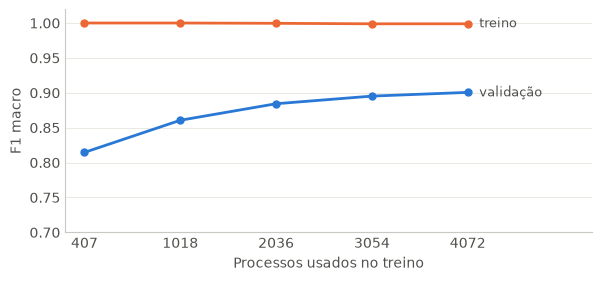

,treino,validação
407,1.000000,0.814593
1018,1.000000,0.860650
2036,0.999577,0.884337
3054,0.998861,0.895256
4072,0.998864,0.900584


In [20]:
tamanhos, tr, va = learning_curve(
    make_pipeline(preprocessador(False), lr()).set_params(**busca.best_params_), Xc, y_dev, groups=g_dev,
    cv=cv_dev(), scoring="f1_macro", train_sizes=[0.1, 0.25, 0.5, 0.75, 1.0], n_jobs=N_JOBS)
fig_linha([int(t) for t in tamanhos], [("treino", tr.mean(axis=1), CORES["ativo"]), ("validação", va.mean(axis=1), CORES["arquivado"])],
          "Processos usados no treino", "F1 macro", "fig_aprendizado.png", ylim=(0.7, 1.02))
pd.DataFrame({"treino": tr.mean(axis=1), "validação": va.mean(axis=1)}, index=tamanhos)

## Arquivos das figuras

As 11 figuras ficam em `figuras/`. No Colab, baixe pelo painel de arquivos ou com a célula abaixo.

In [21]:
import shutil
shutil.make_archive("figuras", "zip", FIGURAS)
try:
    from google.colab import files
    files.download("figuras.zip")
except ImportError:
    print("figuras.zip gravado na pasta do notebook")

figuras.zip gravado na pasta do notebook
